# PRIMER TRABAJO DE BIOFÍSICA

IAGO DEAÑO RODRÍGUEZ

JAVIER GÓMEZ FIDALGO

AURORA AIDA CABADO GOÁS

## Descripción del trabajo

En este documento exponemos el primer trabajo de la materia Biofísica. El trabajo consiste en analizar y filtrar una base de datos para crear un modelo predictivo a partir de la misma. En nuestro caso concreto, hemos elegido una base de datos sobre tipos de setas *mushroooms.csv*. Nuestro objetivo es determinar la clase ('*class*') de cada seta, haciendo un análisis del resto de parámetros de las columnas, de esta manera determinaremos si es comestible ('*edible*') o venenosa ('*poisonous*').

Nuestro programa analizará parte de estos datos como entrenamiento (*train*) y devolverá unos resultados a partir de los restantes (*test*). Lo haremos a partir de tres métodos; el primero será la validación cruzada, el segundo será una red neuronal y el último será un árbol de decisión. Al final, analizaremos los resultados y determinaremos cuál de estos tres procedimientos es mejor para predecir si nuestra seta es o no comestible.

## PARTE 1: Procesamiento de datos

### Paso 1
Importamos nuestro documento y creamos un iterable de pandas, lo que nos permite trabajar con nuestros datos de una forma mucho más cómoda. Visualizamos las primeras líneas de nuestros datos importados para comprobar que todo está en orden. Comprobamos también qué nombre tiene cada columna de nuestro archivo para poder llamar a cada una en caso de ser necesario.

In [1]:
import pandas as pd

df = pd.read_csv('mushrooms.csv')
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [2]:
df.columns

Index(['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
       'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
       'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
       'stalk-surface-below-ring', 'stalk-color-above-ring',
       'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number',
       'ring-type', 'spore-print-color', 'population', 'habitat'],
      dtype='str')

### Paso 2
Vamos a eliminar las columnas que no nos aportan información, en este caso la columna '*veil-type*' sólo tiene un valor para todos los casos por lo que no va a servir para determinar si una seta es venenosa o no. Así no sólo evitamos confusiones, si no que también simplificamos la tarea de procesamiento de datos.

In [3]:
df = df.drop('veil-type', axis=1) # antes disto debería ver que tipos de variables toma
# cada un por cela así podemos asegurarnos de eliminalo adecuadamente, co código <<df['nome columna'].unique()>> (creo)
# poderiamos facer unha lista creo que da forma 

# for i in range(len(df.columns)):
#   print(f'na columna {df.columns[i]} pódense tomar os seguintes valores {df['df.columns[i]'].unique()}')

# tamén poderiamos facer algo rollo "if len(df.columns[i]) == 1 entón elimina a columna"

In [4]:
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,s,w,w,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,s,w,w,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,s,w,w,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,s,w,w,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,s,w,w,w,o,e,n,a,g


### Paso 3
Ahora vamos a renombrar nuestra columna '*class*' y la cambiamos por 'muerte'. Esto lo hacemos porque '*class*' es una función de python y nos va a dar problemas con alguna de las funciones para interaccionar con las columnas. Intercambiamos todas las filas aleatoriamente para que asegurarnos de que nuestros datos no siguen un orden determinado que asuma nuestra máquina y desarrolle un modelo que no se ajusta correctamente a los datos. Definimos nuestra variable de estudio 'y'.

In [5]:
df = df.rename(columns={'class':'muerte'})
df.head()

,muerte,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,s,w,w,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,s,w,w,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,s,w,w,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,s,w,w,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,s,w,w,w,o,e,n,a,g


In [6]:
df = df.sample(frac=1)
df.head()

,muerte,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-color,ring-number,ring-type,spore-print-color,population,habitat
599,p,x,s,n,t,p,f,c,n,n,...,s,s,w,w,w,o,p,k,s,u
1196,e,x,f,g,f,n,f,w,b,k,...,f,s,w,w,w,o,e,k,s,g
2842,e,x,y,n,t,n,f,c,b,p,...,s,s,g,g,w,o,p,n,y,d
244,e,f,f,w,t,a,f,w,n,p,...,s,s,w,w,w,o,p,u,v,d
6904,e,x,y,c,t,n,f,c,b,w,...,s,s,w,w,w,t,p,w,y,p


In [7]:
y = df.muerte
print(y)

599     p
1196    e
2842    e
244     e
6904    e
       ..
3336    e
3798    e
1148    e
5375    p
5829    p
Name: muerte, Length: 8124, dtype: str


### Paso 4
Ahora vamos a separar nuestra variable de estudio del resto de datos. Ya tenemos la variable de estudio en el elemento 'y', por lo que sólo tenemos que sacar nuestra otra variable 'X', que será el resto de nuestros datos, EXCEPTO los de 'y'. Esta variable tiene un problema y es que todas las columnas, excepto la de muerte, son variables categóricas nominales, sin relación de orden entre sus categorías. Por lo tanto, es más apropiado transformarlas en variables que representan cada categoría de manera independiente haciendo uso de la función 'get_dummies'.

In [8]:
X = df.drop('muerte', axis=1)
X.head()

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-color,ring-number,ring-type,spore-print-color,population,habitat
599,x,s,n,t,p,f,c,n,n,e,...,s,s,w,w,w,o,p,k,s,u
1196,x,f,g,f,n,f,w,b,k,t,...,f,s,w,w,w,o,e,k,s,g
2842,x,y,n,t,n,f,c,b,p,t,...,s,s,g,g,w,o,p,n,y,d
244,f,f,w,t,a,f,w,n,p,t,...,s,s,w,w,w,o,p,u,v,d
6904,x,y,c,t,n,f,c,b,w,e,...,s,s,w,w,w,t,p,w,y,p


In [9]:
X_dummy = pd.get_dummies(X)
X_dummy.head()

,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
599,False,False,False,False,False,True,False,False,True,False,...,True,False,False,False,False,False,False,False,True,False
1196,False,False,False,False,False,True,True,False,False,False,...,True,False,False,False,True,False,False,False,False,False
2842,False,False,False,False,False,True,False,False,False,True,...,False,False,True,True,False,False,False,False,False,False
244,False,False,True,False,False,False,True,False,False,False,...,False,True,False,True,False,False,False,False,False,False
6904,False,False,False,False,False,True,False,False,False,True,...,False,False,True,False,False,False,False,True,False,False


### Paso 5
Ahora lo que vamos hacer es transformar nuestros datos de la columna 'y' en números, usaremos una función llamada '*.replace*'.

In [10]:
y = y.replace(['p','e'],[0,1])
y.head()

599     0
1196    1
2842    1
244     1
6904    1
Name: muerte, dtype: object

### Paso 6
Vamos ahora a crear nuestros conjuntos de entrenamiento y prueba, decidimos dividir nuestro conjunto en un 80 % de datos para el entrenamiento y un 20% de datos para la prueba. Comprobamos que nuestros conjuntos tienen el tamaño adecuado.

In [11]:
split = round(X.shape[0]*0.80)
X_train, X_test = X_dummy[:split], X_dummy[split:]
y_train, y_test = y[:split], y[split:]

In [12]:
print('Tamaños de X_train', X_train.shape)
print('Tamaños de X_test', X_test.shape)
print('Tamaños de Y_train', y_train.shape)
print('Tamaños de Y_test', y_test.shape)

Tamaños de X_train (6499, 116)
Tamaños de X_test (1625, 116)
Tamaños de Y_train (6499,)
Tamaños de Y_test (1625,)


## PARTE 2: Validación cruzada

### Paso 1
Ahora implementamos la validación cruzada, importamos los módulos que necesitamos y creamos nuestro modelo de validación cruzada. Primero calculamos el alfa que hace máxima la exactitud media de la validación cruzada, para ello utilizamos la función de pérdida '*hinge*', el tipo de regularización '*l2*' y 5 particiones del conjunto de datos.

In [ ]:
import numpy as np
from sklearn import linear_model
from sklearn import model_selection as ms

alpha = np.arange(1e-15, 1, 0.005)
val_scores = np.zeros((len(alpha), 1)) 

for i in range(len(alpha)): 
    model_cross = linear_model.SGDClassifier(loss='hinge', penalty='l2', alpha=alpha[i]) 
    score = ms.cross_val_score(model_cross, X_train, y_train, cv=5)
    val_scores[i] = score.mean()
#esta funcion puede tardar unos cuantos segundos en ejecutarse

ind = np.argmax(val_scores)
print('El mejor valor de alpha es', alpha[ind])

El mejor valor de alpha es 1e-15


### Paso 2
Creamos nuestro modelo de validación cruzada. Utilizamos la función de pérdida y el tipo de regularización anteriores debido a que con estos parámetros se obtienen los mejores resultados y el valor de alpha obtenido. Entrenamos a la máquina con los datos de entrenamiento y calculamos la exactitud de este.

In [ ]:
model_star = linear_model.SGDClassifier(loss='hinge', penalty='l2', alpha=alpha[ind])
model_trained = model_star.fit(X_train, y_train)

print('La exactitud del entrenamiento es', model_trained.score(X_train, y_train))

### Paso 3
Aplicamos nuestro modelo a los datos de entrenamiento para comprobar que no nos da ningún error y que obtenemos un array de ceros y unos. Una vez entrenado podemos comprobar la eficacia de nuestra red neuronal con los datos de prueba.

In [111]:
y_hat_train_1 = model_trained.predict(X_train)
print(y_hat_train_1[:5])

[0 0 0 1 0]


In [112]:
y_hat_test_1 = model_trained.predict(X_test)
print(y_hat_test_1[:5])

[1 1 1 0 0]


### Paso 4
Analizamos los resultados con nuestra matriz de confusión de los datos de prueba para saber cuántos verdaderos positivos (venenosos y el modelo predijo venenosos), falsos positivos (venenosos y el modelo predijo comestibles), falsos negativos (comestibles y el modelo predijo venenosos) y verdaderos negativos (comestibles y el modelo predijo comestibles) tenemos. La representamos como un mapa de calor para poder ver gráficamente toda esta información.

La cantidad de verdaderos positivos es  846
La cantidad de falsos positivos es  0
La cantidad de falsos negativos es  0
La cantidad de verdaderos negativos es  779
[[779   0]
 [  0 846]]


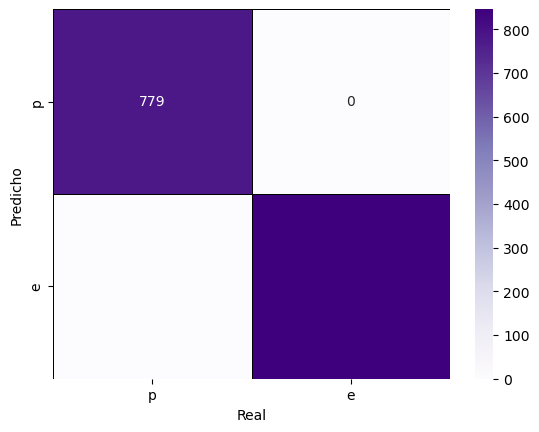

In [114]:
from sklearn.metrics import confusion_matrix

cm_1 = confusion_matrix(y_test, y_hat_test_1, labels=[0,1])

TN_1, FP_1, FN_1, TP_1 = cm_1.flatten()
print('La cantidad de verdaderos positivos es ', TP_1)
print('La cantidad de falsos positivos es ', FP_1)
print('La cantidad de falsos negativos es ', FN_1)
print('La cantidad de verdaderos negativos es ', TN_1)

print(cm_1)

import seaborn as sns
import matplotlib.pyplot as plt

labels_1 = ['p', 'e']
sns.heatmap(cm_1, cmap='Purples', annot=True, fmt='d', linewidths=0.5, linecolor='black', xticklabels=labels_1, yticklabels=labels_1) #Graficamos la matriz de confusión en escala de colores violeta, hacemos que aparezcan los valores de los resultados (en forma de números enteros) y sus clases y que la separación de los resultados sea una línea negra
plt.ylabel('Predicho') #Ponemos título al eje y
plt.xlabel('Real') #Ponemos título al eje x
plt.show() #Hacemos que se muestre el mapa de calor

Seguimos estudiando los resultados con varias métricas de evaluación.

In [116]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_hat_test_1))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       779
           1       1.00      1.00      1.00       846

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



## PARTE 3: Red Neuronal

### Paso 1
Ahora implementamos nuestra red neuronal, importamos todos los paquetes que necesitamos y creamos nuestro modelo de red neuronal ('*model*'). Tras hacer varias pruebas y comprobar la bibliografía, los mejores resultados se obtienen con 3 capas de de 30 neuronas cuya función de activación es 'relu' y otra capa con una neurona de output cuya función de activación es '*sigmoid*'. Luego, pusimos una tasa de aprendizaje (*learning rate*) muy baja para tener una mayor precisión en nuestro resultado y que el modelo avance con pasos más pequeños en lugar de pasos muy grandes, para este tipo de estudio es el parámetro más adecuado. Usamos el optimizador 'sgd' para ajustar los pesos al modelo, minimizando la función de pérdida ('*loss*'), la función de pérdida es '*binary_crossentropy*' porque queremos un resultado en código binario, es decir, comestible ('1') o venenosa ('0'). Por último la entrenamos con los datos de entrenamiento usando 50 etapas para tener más tiempo de procesamiento y mejorar la fiabilidad y lotes de 10 datos para actualizar los pesos de la red neuronal más frecuentemente.

In [119]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import SGD

model = keras.Sequential([
    layers.Input(shape=(116,)),
    layers.Dense(30, activation='relu'),
    layers.Dense(30, activation='relu'),
    layers.Dense(30, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

sgd = SGD(learning_rate=0.001)
model.compile(optimizer='sgd',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

model.fit(X_train, y_train, epochs=50, batch_size=10)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 30)             │         3,510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 30)             │           930 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 30)             │           930 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,401 (21.10 KB)

 Trainable params: 5,401 (21.10 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
650/650 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7982 - loss: 0.4569
Epoch 2/50
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9861 - loss: 0.0597
Epoch 3/50
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9971 - loss: 0.0225
Epoch 4/50
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9988 - loss: 0.0109
Epoch 5/50
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9992 - loss: 0.0068  
Epoch 6/50
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 967us/step - accuracy: 0.9998 - loss: 0.0039
Epoch 7/50
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 1.0000 - loss: 0.0033
Epoch 8/50
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 1.0000 - loss: 0.0021
Epoch 9/50
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 1.0000 - loss: 0.0017
Epoch 10/50
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 1.0000 - loss: 0.0014
Epoch 11/50
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 1.0000 - loss: 0.0011
Epoch 12/50
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 942u

### Paso 2
Aplicamos nuestro modelo a los datos de entrenamiento para comprobar que no nos da ningún error y que obtenemos un array de ceros y unos. Una vez entrenado podemos comprobar la eficacia de nuestra red neuronal con los datos de prueba.

In [121]:
y_hat_train = model.predict(X_train).round()
y_hat_train[:5]

204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 960us/step


array([[0.],
       [0.],
       [0.],
       [1.],
       [0.]], dtype=float32)

In [122]:
y_hat_test = model.predict(X_test).round()
y_hat_test[:5]

51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 992us/step


array([[1.],
       [1.],
       [1.],
       [0.],
       [0.]], dtype=float32)

### Paso 3
Analizamos los resultados con nuestra matriz de confusión de los datos de prueba para saber cuántos verdaderos positivos (venenosos y el modelo predijo venenosos), falsos positivos (venenosos y el modelo predijo comestibles), falsos negativos (comestibles y el modelo predijo venenosos) y verdaderos negativos (comestibles y el modelo predijo comestibles) tenemos. La representamos como un mapa de calor para poder ver gráficamente toda esta información.

La cantidad de verdaderos positivos es  846
La cantidad de falsos positivos es  0
La cantidad de falsos negativos es  0
La cantidad de verdaderos negativos es  779
[[779   0]
 [  0 846]]


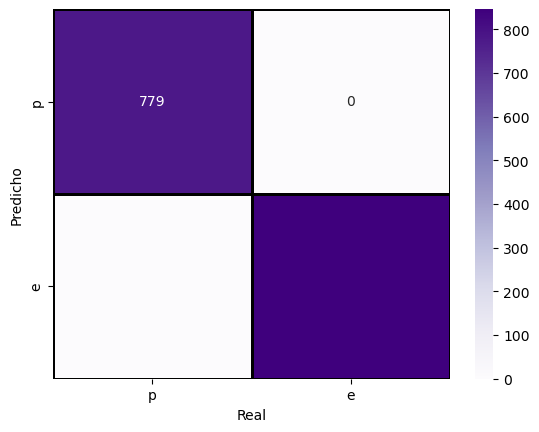

In [124]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_hat_test, labels=[0,1])

TN, FP, FN, TP = cm.flatten()
print('La cantidad de verdaderos positivos es ', TP)
print('La cantidad de falsos positivos es ', FP)
print('La cantidad de falsos negativos es ', FN)
print('La cantidad de verdaderos negativos es ', TN)

print(cm)

import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(cm, cmap='Purples', annot=True, fmt='d', linewidths=1, linecolor='black', xticklabels=labels_1, yticklabels=labels_1) #Graficamos la matriz de confusión en escala de colores violeta, hacemos que aparezcan los valores de los resultados (en forma de números enteros) y sus clases y que la separación de los resultados sea una línea negra
plt.ylabel('Predicho') #Ponemos título al eje y
plt.xlabel('Real') #Ponemos título al eje x
plt.show() #Hacemos que se muestre el mapa de calor

Seguimos estudiando los resultados con varias métricas de evaluación.

In [126]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=1)

from sklearn.metrics import classification_report
print(classification_report(y_test, y_hat_test))

51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 1.0000 - loss: 1.1117e-04 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       779
           1       1.00      1.00      1.00       846

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



## PARTE 4: Árboles de decisión

### Paso 1
Importamos nuestro modelo de clasificación en forma de arbol de decisión, importamos los módulos que necesitamos, creamos nuestros conjuntos de datos, los separamos al igual que en los anteriores procedimientos, es decir, 20% prueba y 80% entrenamiento, hacemos que los conjuntos de entrenamiento y prueba sean diferentes cada vez que ejecutamos el programa y que la proporción de las dos clases sea la misma en ambos conjuntos.

In [129]:
from sklearn.tree import DecisionTreeClassifier

In [130]:
from sklearn.model_selection import train_test_split

y_text=df.muerte

In [131]:
X_trainset, X_testset, y_trainset, y_testset = train_test_split(X_dummy, y_text, test_size=0.2, random_state=1, stratify=y_text)

### Paso 2
Ahora tenemos que decidir qué criterio usamos en el árbol de decisión. El criterio de la entropía mide el grado de impureza de los datos, de esta forma maximizamos la ganancia de información, además hacemos 6 etapas de decisión, así permitimos al modelo tener mayor precisión al poder usar más criterios de clasificación. Entrenamos a la máquina con los datos de entrenamiento.

In [133]:
arbolseta = DecisionTreeClassifier(criterion='entropy', max_depth = 6)
arbolseta

DecisionTreeClassifier(criterion='entropy', max_depth=6)

In [134]:
arbolseta.fit(X_trainset, y_trainset)

DecisionTreeClassifier(criterion='entropy', max_depth=6)

### Paso 3
Comparamos los resultados de nuestro modelo predictivo con los reales y vemos que todo funciona correctamente.

In [136]:
predTree = arbolseta.predict(X_testset)

In [137]:
print(predTree[0:5])
print(y_testset[0:5])

['p' 'p' 'e' 'p' 'p']
6077    p
5493    p
1686    e
7383    p
6041    p
Name: muerte, dtype: object


### Paso 4
Por último comprobamos la precisión de nuestro arbol de decisión y mostramos dos representaciones diferentes del árbol de decisión.

In [139]:
from sklearn import metrics

print('La exactitud del árbol de decisiones es', metrics.accuracy_score(y_testset, predTree))

La exactitud del árbol de decisiones es 1.0


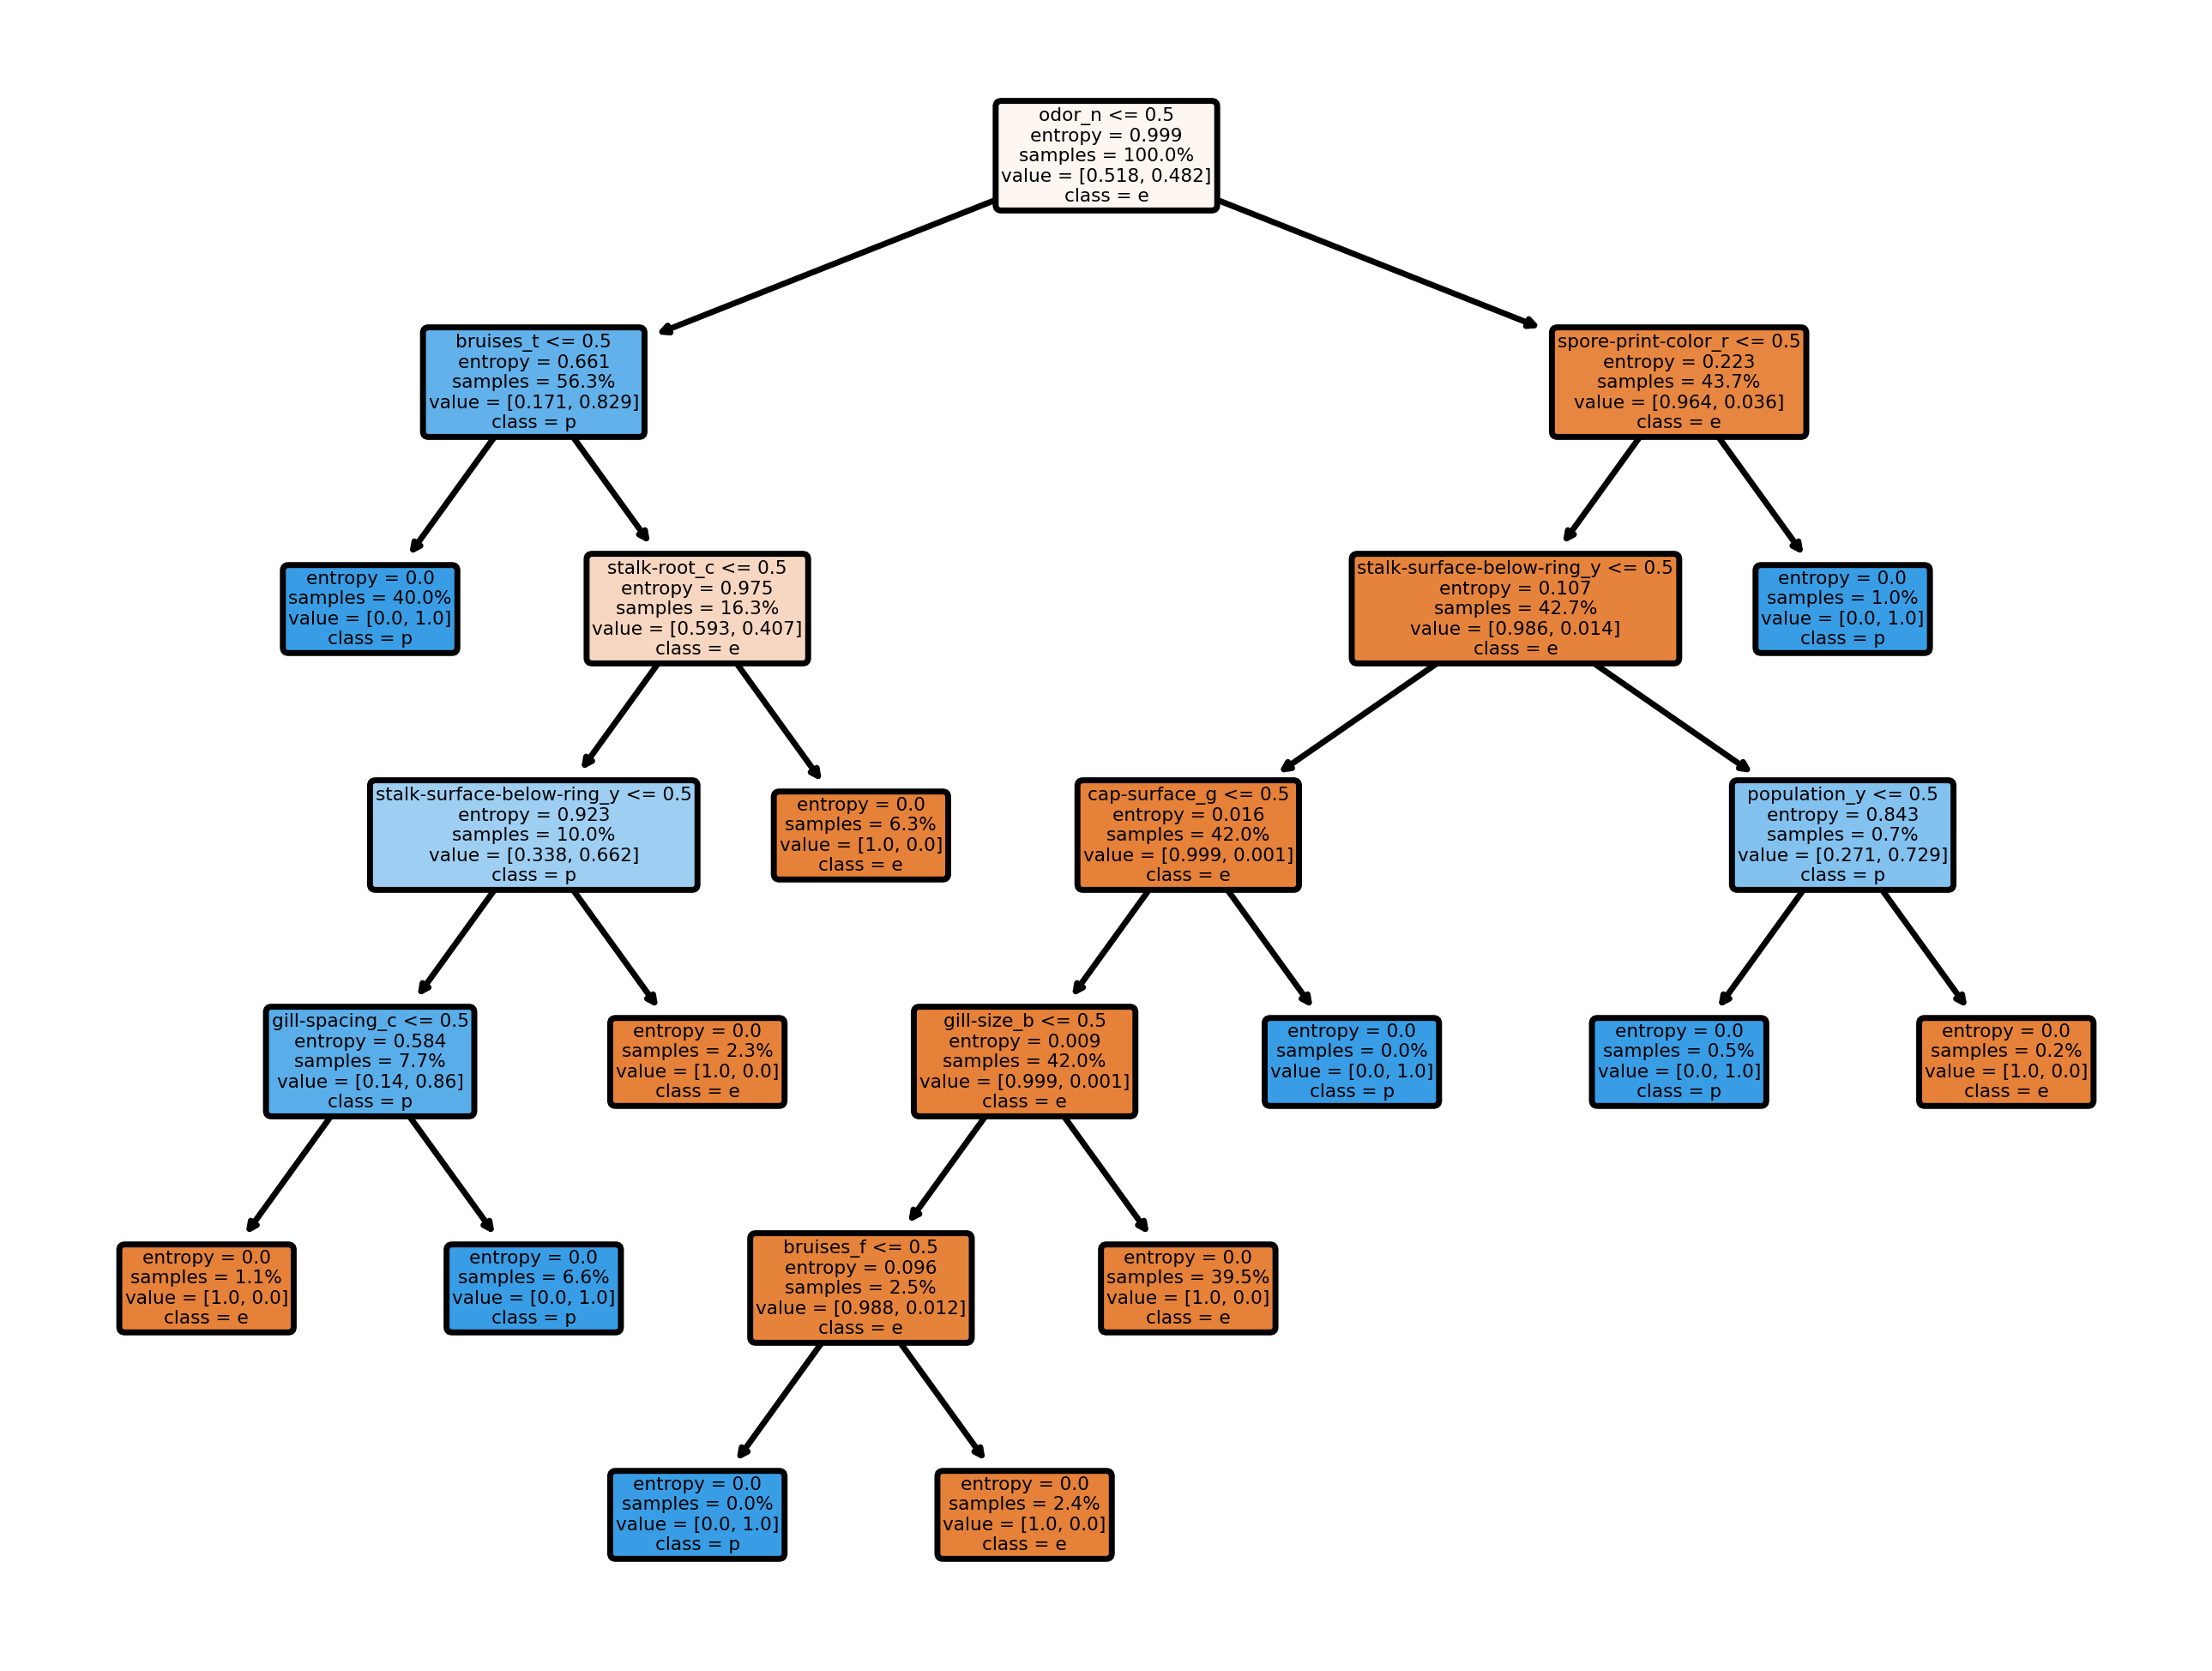

In [140]:
from sklearn.tree import plot_tree

plt.figure(dpi=500)  #Ponemos la calidad de la imagen
featureNames = X_dummy.columns[0:116] #Importa el nombre de las columnas
plot_tree(arbolseta, feature_names=featureNames, class_names= arbolseta.classes_, filled=True, proportion=True, rounded=True) #Graficamos el árbol, ponemos el nombre de las columnas, las clases de los resultados (p o e) y colores a las celdas, hacemos que aparezcan los porcentajes de las muestras y redondeamos las esquinas de las celdas)
plt.show() #Hacemos que se muestre el árbol de decisión

In [141]:
#Para la siguiente celda del programa es probable que sean necesarias las funciones
#! pip install pydotplus y #!pip install graphviz
#Igualmente no es imprescindible, sólo genera un jpg del árbol y lo guarda automáticamente

In [142]:
from io import StringIO
from sklearn import tree
import pydotplus
import matplotlib.image as mpimg

dot_data = StringIO()
filename = "setas.png"
out = tree.export_graphviz(arbolseta, feature_names=featureNames, out_file=dot_data, class_names=arbolseta.classes_, filled=True, proportion=True, rounded=True) #Graficamos el árbol, ponemos el nombre de las columnas, las clases de los resultados (p o e) y colores a las celdas, hacemos que aparezcan los porcentajes de las muestras y redondeamos las esquinas de las celdas) 
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
graph.write_png(filename) #Hacemos que se cree un archivo con el árbol de decisión con un determinado nombre
img = mpimg.imread(filename)
plt.figure(dpi=500) #Ponemos la calidad de la imagen
plt.imshow(img)
plt.show() #Hacemos que se muestre el árbol de decisión

InvocationException: Program terminated with status: 3221225477. stderr follows: []

## PARTE 5: Conclusiones

### Red neuronal y validación cruzada
Todas las setas de nuestro conjunto de prueba (1625) han sido clasificadas correctamente. Existe un margen de error muy pequeño en sus predicciones, por lo que podría decirse que estar red neuronal es bastante fiable. Sin embargo, una precisión casi igual a la unidad puede ser indicador de "overfitting", esto es, que nuestra red neuronal puede predecir con máxima precisión y sin desviación solamente las variables de la base de datos que poseemos (algo que se podría tachar de inaudito, al estar haciendo uso de estadísticas sobre una población limitada). Hay una posibilidad de que, si usamos un dato externo a la base, prediga su comestibilidad incorrectamente (aunque esto ya puede observarse con algunos datos del conjunto, lo cual es una desviación casi despreciable comparada con el número de datos). Sin embargo, esto podría ser porque la precisión es tan próxima a 1 que se aproxima automáticamente. Otra posibilidad es que la alta cantidad y fiabilidad de los datos nos entrene un red muy precisa.

### Árbol de decisión
Uno podría decidir inicialmente que un árbol de decisión podría ser la forma más efectiva de crear un modelo predictivo para esta base da datos. Sin embargo, puede observarse en el procedimiento que, igual que en la creación de la matriz de confusión, tenemos una precisión igual a unidad (o increíblemente próxima). Esto, otra vez, podría deberse a overfitting, o que nuestra base de datos es increíblemente fiable, y resulta bastante convincente este factor, dado que se ha calculado la matriz de confusión y el árbol de decisión de dos maneras cada uno. Igualmente, tenemos un modelo predictivo que al parecer nos puede predecir con gran exactitud un dato dado, y por ello se podría concluir que, efectivamente, hemos alcanzado nuestro objetivo de evitar que nuestros comensales perezcan.

### Conclusión general
Tras analizar pormenorizadamente todos los modelos, podemos concluir que todos predicen bastante bien la comestibilidad de nuestras setas teniendo en cuenta esos pequeños detalles que comentábamos. Igualmente, si nos tenemos que decantar por uno sería por el árbol de decisión, que tiene una muy buena precisión y además incluye una visualización gráfica que nos permite entender cómo trabaja nuestro modelo, permitiéndonos así buscar patrones que nos ayuden a estudiar la naturaleza de las setas en mayor profundidad.